# Noise Ablation for the Interventional MMD Flow: Injected vs. Additive Noise (ColorMNIST)

The MMD gradient flow admits two distinct ways of adding randomness to the particle
dynamics, which are often conflated. This notebook defines both, explains why they are
*not* interchangeable, and measures them on the ColorMNIST counterfactual design with a
cross-fitted doubly robust target — everything except the noise held fixed.

The estimation half of the pipeline (design, autoencoder, DR weights, kernel, initial
particles) is identical to the arm-1 notebook and is computed once, so every difference
reported below is attributable to the noise mechanism alone.

In [1]:
import sys
import numpy as np
import torch
import matplotlib.pyplot as plt

sys.path.append("../../src")
torch.set_default_dtype(torch.float32)

from data_utils import (color_ratio, load_digit_pools, sample_interventional,
                        sample_observed, to_image_range, to_model_range)
from autoencoder_utils import encode_in_batches, train_conv_ae
from kernel_utils import IMQKernel, RBF, imq_c_from_median
from causality_utils import (cpme_dr_weights_crossfit, make_crossfit_fold_ids,
                             select_regularization)
from dens_ratio_utils import crossfit_propensity
from mmd_flow_utils import (constant_noise, halving_noise, mmd_gradient_flow,
                            noise_until, squared_mmd)
from metric_utils import sliced_wasserstein

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## 1. The Two Noise Mechanisms

Write the empirical witness at iteration $n$ as
$$
\widehat f_n(z)
= \frac1M\sum_{\ell} k(z, Y_n^{(\ell)}) - \widehat s_\pi(z),
\qquad
\widehat s_\pi(z) = \sum_i v_i\, k(z, y_i),
$$
with $\{v_i\}$ the cross-fitted DR weights. The two updates are

$$
\textbf{injected:}\quad
Y_{n+1}^{(j)} = Y_n^{(j)} - \gamma\, \nabla \widehat f_n\!\big(Y_n^{(j)} + \beta_n u_n^{(j)}\big),
\qquad
\textbf{additive:}\quad
Y_{n+1}^{(j)} = Y_n^{(j)} - \gamma\, \nabla \widehat f_n\!\big(Y_n^{(j)}\big) + \beta_n u_n^{(j)},
$$

with $u_n^{(j)} \sim \mathcal N(0, I)$. The difference is *where* $\beta_n$ enters.

**Injected noise** (Arbel et al., 2019, Algorithm 1) perturbs only the point at which the
gradient is read; the particle state stays deterministic. Since
$\mathbb E_u[\nabla \widehat f(\cdot + \beta u)] = \nabla(\widehat f * \varphi_\beta)$, it
is a Gaussian *smoothing of the velocity field*. Its purpose is to escape the flat regions
where the witness gradient vanishes because particles sit far from the target relative to
the kernel bandwidth: the mollified gradient still "sees" the target from a distance. The
minimiser of the objective is unchanged, so the noise need not be annealed for
correctness — only to sharpen the final fit.

**Additive noise** perturbs the particle state itself, superimposing a random walk on the
descent. This is the diffusion of (mean-field) Langevin dynamics: it keeps the particle law
absolutely continuous, which is what the KL-type finite-particle guarantees require. But
it *biases the stationary law* — the dynamics equilibrate between the objective and an
entropy term of size $\beta^2/(2\gamma)$ rather than converging to the minimiser — so
$\beta_n$ must be annealed to zero to remove the bias.

**They are not comparable at equal $\beta$.** Additive noise displaces a particle by
$\beta$ per step, accumulating $\sqrt{R}\,\beta$ over $R$ steps. Injected noise displaces
it only indirectly, through the change it induces in the gradient, which is of order
$\gamma \beta \cdot \lVert \nabla^2 \widehat f\rVert$. Below, $\beta$ is therefore
expressed in units of the kernel scale $c$ and each mechanism is swept over its own grid,
two orders of magnitude apart.

## 2. Data, Autoencoder, and Cross-Fitted DR Target

The ColorMNIST design of Dance et al. (2026): a latent confounder $X \sim U[0,1]$ sets both
the treatment odds and the digit colour, so the observed arm $a = 1$ skews red while the
interventional law $P(Y(1))$ carries the population colour mixture. The flow runs in the
32-dimensional latent of a convolutional autoencoder, and the target is the cross-fitted DR
embedding over a 4000-point support subsample.

In [2]:
N_OBS, TARGET_A = 20000, 1
W_CONF, TAU = 10.0, 0.08
N_DR, M, N_ITER = 4000, 1600, 3000

pools = load_digit_pools(root="../../data", device=device)
generator = torch.Generator(device=device).manual_seed(SEED)
X_obs, A_obs, Y_obs = sample_observed(pools, N_OBS, w_conf=W_CONF, tau=TAU,
                                      generator=generator)
data = to_model_range(Y_obs)
arm = A_obs == TARGET_A

ae, history_ae = train_conv_ae(data, latent_dim=32, n_iterations=3000, batch_size=128,
                               learning_rate=1e-3, device=device,
                               generator=torch.Generator(device=device).manual_seed(SEED),
                               log_every=1500, verbose=False)
for parameter in ae.parameters():
    parameter.requires_grad_(False)
print(f"n = {N_OBS}   arm a={TARGET_A} size = {int(arm.sum())}   "
      f"reconstruction MSE {history_ae[-1][1]:.4f}")

n = 20000   arm a=1 size = 9923   reconstruction MSE 0.0025


In [3]:
subsample = torch.randperm(N_OBS, generator=torch.Generator(device=device).manual_seed(SEED + 5),
                           device=device)[:N_DR]
X_s, A_s = X_obs[subsample], A_obs[subsample]
Z_s = encode_in_batches(ae.encode, data[subsample])

fold_ids = make_crossfit_fold_ids(N_DR, n_folds=5, seed=0)
torch.manual_seed(SEED)
e1 = crossfit_propensity(X_s.unsqueeze(1).double().cpu(), A_s.double().cpu(), fold_ids)
w_hat = (A_s.cpu() == TARGET_A).double() / (e1 if TARGET_A == 1 else 1.0 - e1)

kernel_x = RBF(use_length_scale_heuristic=True)
K_x = kernel_x(X_s.unsqueeze(1).double().cpu())
K_a = (A_s[:, None] == A_s[None, :]).double().cpu()
K_a_target = (A_s == TARGET_A).double().cpu()[:, None].expand(N_DR, N_DR).contiguous()
K_pair = K_x * K_a
fold_lambdas = {}
for fold in np.unique(fold_ids):
    train = np.where(fold_ids != fold)[0]
    fold_lambdas[int(fold)], _ = select_regularization(K_pair[train][:, train],
                                                       Z_s[train, 0].double().cpu(), seed=0)
v_dr = cpme_dr_weights_crossfit(K_x, K_a, K_a_target, w_hat, fold_ids,
                                fold_lambdas).float().to(device)

Z_arm = encode_in_batches(ae.encode, data[arm])
pick = torch.randperm(Z_arm.shape[0], generator=torch.Generator(device=device).manual_seed(SEED + 1),
                      device=device)[:M]
initial_particles = Z_arm[pick].clone()
c_imq = imq_c_from_median(Z_s)
kernel = IMQKernel(c=c_imq, beta=-0.5)
step_size = 0.15 * c_imq ** 2
print(f"DR weights: sum(v) = {v_dr.sum():.3f}   sum|v| = {v_dr.abs().sum():.3f}")
print(f"IMQ c = {c_imq:.2f}   step = {step_size:.1f}   M = {M} particles")

DR weights: sum(v) = 1.000   sum|v| = 1.000
IMQ c = 13.24   step = 26.3   M = 1600 particles


## 3. Two Regimes

Noise can only matter where the noise-free flow has a problem, so the ablation is run in
two regimes that share everything except the kernel and the particle initialisation.

**Regime A — well-conditioned.** The setting of the arm-1 notebook: an IMQ kernel at the
median heuristic, particles initialised at the observed arm. The noise-free flow already
converges here.

**Regime B — dead zone.** A narrow Gaussian kernel ($\ell = c/4$, so the kernel gradient
decays *exponentially*) with the particles displaced $6\ell$ outside its support. The
witness gradient is then vanishingly small and the noise-free flow barely transports. This
is the failure mode noise injection was introduced to address.

Within each regime, each run differs only in `noise_mode`, the scale $\beta_0$, and the
schedule: **constant** $\beta_n = \beta_0$; **halving** every 500 iterations; **until**
$\beta_n = \beta_0$ for the first half then $0$ (Arbel et al., 2019, App. G.2). Scales are
quoted in units of the kernel scale of the regime, and each mechanism gets its own grid —
recall that additive noise displaces a particle by $\beta$ per step whereas injected noise
acts only through the gradient.

In [4]:
_, Y_oracle = sample_interventional(pools, M, a=TARGET_A, tau=TAU,
                                    generator=torch.Generator(device=device).manual_seed(SEED + 9))
_, Y_oracle_2 = sample_interventional(pools, M, a=TARGET_A, tau=TAU,
                                      generator=torch.Generator(device=device).manual_seed(SEED + 10))
flatten = lambda images: images.reshape(images.shape[0], -1)
kernel_pixel = RBF(use_length_scale_heuristic=True)
_ = kernel_pixel(flatten(Y_oracle))

SCHEDULES = {"const": lambda b: constant_noise(b),
             "halving": lambda b: halving_noise(b, halve_every=N_ITER // 6),
             "until": lambda b: noise_until(b, cutoff=N_ITER // 2)}

LENGTH_SCALE = c_imq / 4.0
REGIMES = {
    "A: well-conditioned": dict(
        kernel=IMQKernel(c=c_imq, beta=-0.5), scale=c_imq, step=0.15 * c_imq ** 2,
        init=initial_particles, schedules=("const", "halving", "until"),
        grids={"injected": [0.01, 0.03, 0.1, 0.3, 1.0],
               "additive": [0.0003, 0.001, 0.003, 0.01, 0.03]}),
    "B: dead zone": dict(
        kernel=RBF(length_scale=LENGTH_SCALE), scale=LENGTH_SCALE,
        step=3.0 * LENGTH_SCALE ** 2,
        init=initial_particles + 6.0 * LENGTH_SCALE / initial_particles.shape[1] ** 0.5,
        schedules=("const", "halving"),
        grids={"injected": [0.25, 0.5, 1.0, 2.0, 4.0, 8.0],
               "additive": [0.01, 0.03, 0.1, 0.3, 1.0]}),
}


def score(images_01):
    ratio = color_ratio(images_01).cpu().numpy()
    return dict(sw1=sliced_wasserstein(flatten(images_01), flatten(Y_oracle), p=1, seed=0).item(),
                sw2=sliced_wasserstein(flatten(images_01), flatten(Y_oracle), p=2, seed=0).item(),
                colour=float(ratio.mean()), colour_sd=float(ratio.std()))


def run_flow(regime, mode, beta_rel, schedule):
    cfg = REGIMES[regime]
    noise_schedule = None if beta_rel == 0 else SCHEDULES[schedule](beta_rel * cfg["scale"])
    particles, history = mmd_gradient_flow(
        cfg["kernel"], target_samples=Z_s, initial_particles=cfg["init"],
        step_size=cfg["step"], n_iterations=N_ITER, noise_schedule=noise_schedule,
        noise_mode=mode, target_weights=v_dr, log_every=N_ITER - 1,
        generator=torch.Generator(device=device).manual_seed(SEED + 3), verbose=False)
    with torch.no_grad():
        images = to_image_range(ae.decode(particles))
    result = score(images)
    result.update(obj=history["squared_mmd"][-1], regime=regime, mode=mode,
                  beta_rel=beta_rel, schedule=schedule, particles=particles,
                  transport=float((particles - cfg["init"]).norm(dim=1).mean()))
    return result


results = []
for regime, cfg in REGIMES.items():
    results.append(dict(run_flow(regime, "injected", 0.0, "const"), tag="no noise"))
    for mode in ("injected", "additive"):
        for schedule in cfg["schedules"]:
            for beta_rel in cfg["grids"][mode]:
                results.append(dict(run_flow(regime, mode, beta_rel, schedule),
                                    tag=f"{mode} b={beta_rel:g} {schedule}"))
floor = dict(score(Y_oracle_2), tag="oracle-vs-oracle floor")
print(f"{len(results)} flow runs completed")

54 flow runs completed


## 4. Results

For each regime, the distance to the interventional law as a function of the noise scale,
against the noise-free baseline and the oracle-vs-oracle floor.

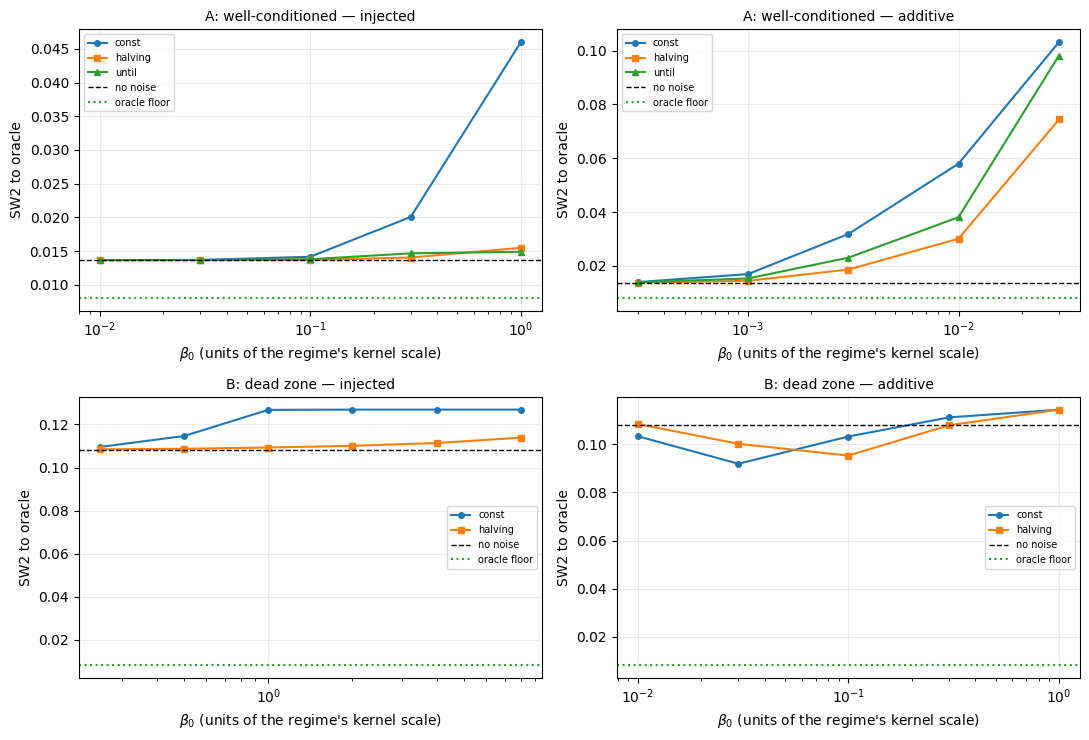

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
for row, regime in enumerate(REGIMES):
    base = next(r for r in results if r["regime"] == regime and r["tag"] == "no noise")
    for col, mode in enumerate(("injected", "additive")):
        ax = axes[row, col]
        for schedule, marker in zip(REGIMES[regime]["schedules"], ("o", "s", "^")):
            pts = [r for r in results if r["regime"] == regime and r["mode"] == mode
                   and r["schedule"] == schedule and r["beta_rel"] > 0]
            ax.plot([r["beta_rel"] for r in pts], [r["sw2"] for r in pts],
                    marker=marker, ms=4, label=schedule)
        ax.axhline(base["sw2"], ls="--", c="k", lw=1, label="no noise")
        ax.axhline(floor["sw2"], ls=":", c="tab:green", lw=1.5, label="oracle floor")
        ax.set_xscale("log")
        ax.set_xlabel(r"$\beta_0$ (units of the regime's kernel scale)")
        ax.set_ylabel("SW2 to oracle")
        ax.set_title(f"{regime} — {mode}", fontsize=10)
        ax.grid(alpha=0.25)
        ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

In [6]:
def best_of(regime, mode):
    return min((r for r in results if r["regime"] == regime and r["mode"] == mode
                and r["beta_rel"] > 0), key=lambda r: r["sw2"])


best = {}
print(f"{'run':40s} {'SW1':>8s} {'SW2':>8s} {'colour mean(sd)':>18s} {'transport':>10s}")
for regime in REGIMES:
    base = next(r for r in results if r["regime"] == regime and r["tag"] == "no noise")
    best[regime] = {m: best_of(regime, m) for m in ("injected", "additive")}
    print(f"-- {regime}")
    for r in (base, best[regime]["injected"], best[regime]["additive"]):
        print(f"   {r['tag']:37s} {r['sw1']:8.4f} {r['sw2']:8.4f} "
              f"{r['colour']:11.3f}({r['colour_sd']:.3f}) {r['transport']:10.2f}")
oracle_ratio = color_ratio(Y_oracle).cpu().numpy()
print(f"\n{'oracle-vs-oracle floor':40s} {floor['sw1']:8.4f} {floor['sw2']:8.4f} "
      f"{oracle_ratio.mean():11.3f}({oracle_ratio.std():.3f})")

run                                           SW1      SW2    colour mean(sd)  transport
-- A: well-conditioned
   no noise                                0.0094   0.0137       0.504(0.280)       3.31
   injected b=0.01 halving                 0.0094   0.0137       0.504(0.280)       3.31
   additive b=0.0003 halving               0.0095   0.0138       0.504(0.280)       3.37
-- B: dead zone
   no noise                                0.0843   0.1081       0.655(0.201)       6.31
   injected b=0.25 halving                 0.0845   0.1085       0.656(0.197)       6.20
   additive b=0.03 const                   0.0730   0.0919       0.627(0.167)      30.85

oracle-vs-oracle floor                     0.0055   0.0081       0.497(0.291)


## 5. How Each Mechanism Fails

Two diagnostics separate them. **Mean transport** shows what the noise does to the
particles: injected noise at or above the kernel scale flattens the mollified velocity
field and freezes the flow, while additive noise inflates transport in proportion to
$\beta$ regardless of whether that motion is useful. The **objective**
$\lVert \mu_Q - \hat\chi_{\mathrm{DR}}\rVert^2$ shows the bias: under annealing the
injected runs return to the noise-free value, whereas the additive runs at constant
$\beta$ settle at an inflated one, which is exactly the entropy-biased equilibrium of the
Langevin dynamics.

In [7]:
regime_a = "A: well-conditioned"
rows = [r for r in results if r["regime"] == regime_a and r["schedule"] == "const"
        and (r["beta_rel"] > 0 or r["tag"] == "no noise")]
print(f"{regime_a}, constant schedule")
print(f"{'run':34s} {'SW2':>8s} {'objective':>11s} {'transport':>10s} {'colour sd':>10s}")
for r in sorted(rows, key=lambda r: (r["mode"], r["beta_rel"])):
    print(f"{r['tag']:34s} {r['sw2']:8.4f} {r['obj']:11.2e} {r['transport']:10.2f} "
          f"{r['colour_sd']:10.3f}")

A: well-conditioned, constant schedule
run                                     SW2   objective  transport  colour sd
additive b=0.0003 const              0.0139    1.01e-05       3.56      0.280
additive b=0.001 const               0.0169    2.05e-05       5.12      0.273
additive b=0.003 const               0.0318    2.35e-04       9.75      0.236
additive b=0.01 const                0.0580    7.80e-03      22.08      0.182
additive b=0.03 const                0.1032    4.45e-02     117.53      0.158
no noise                             0.0137    9.69e-06       3.31      0.280
injected b=0.01 const                0.0137    9.75e-06       3.31      0.280
injected b=0.03 const                0.0137    1.01e-05       3.31      0.280
injected b=0.1 const                 0.0142    1.57e-05       3.27      0.273
injected b=0.3 const                 0.0201    7.41e-05       3.08      0.228
injected b=1 const                   0.0460    1.23e-03       0.51      0.195


## 6. Decoded Samples

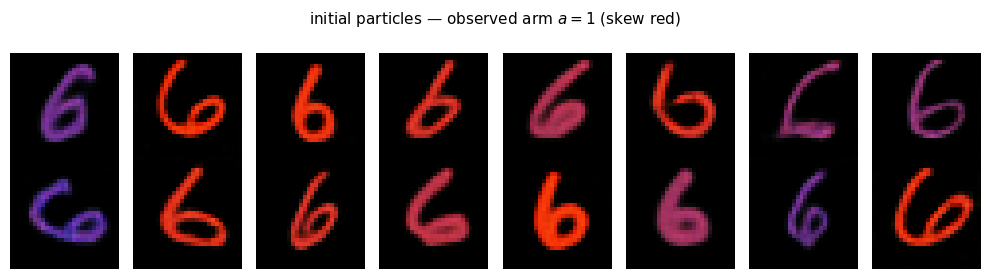

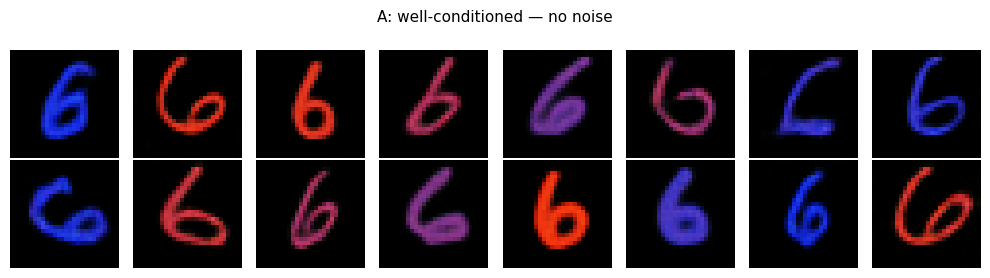

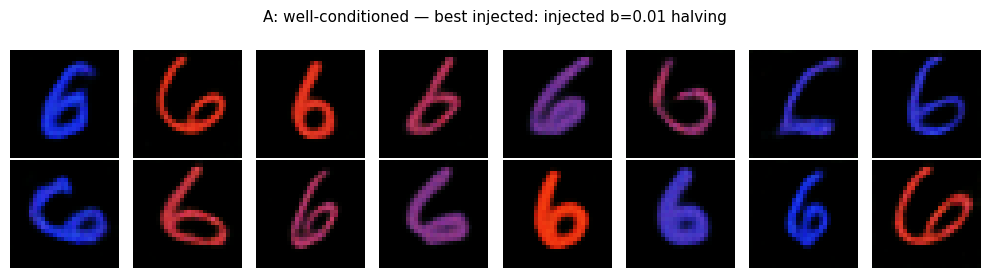

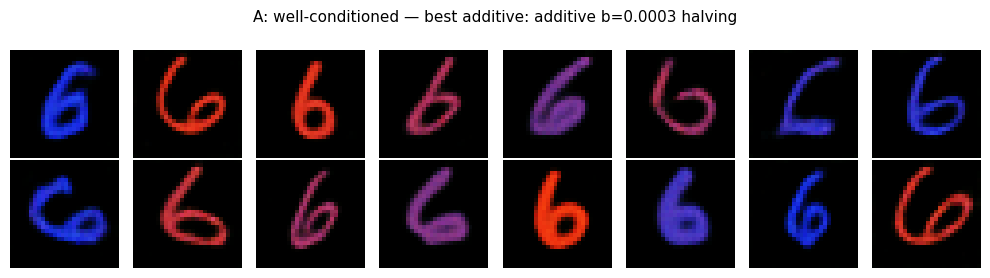

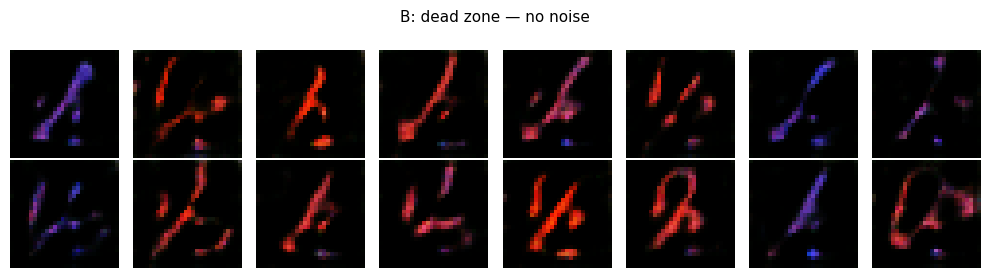

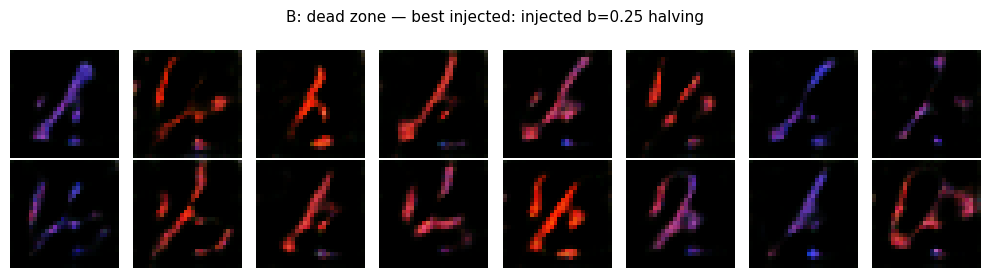

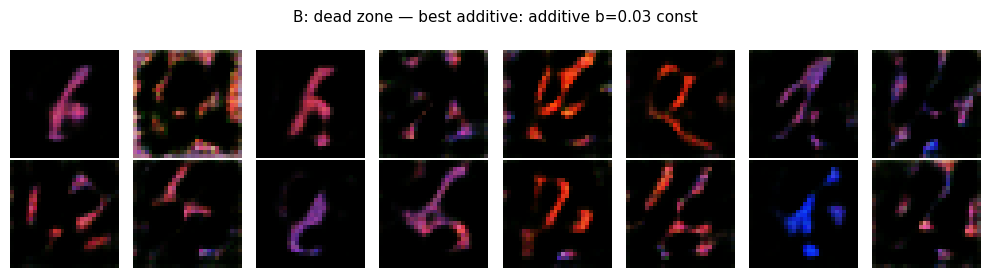

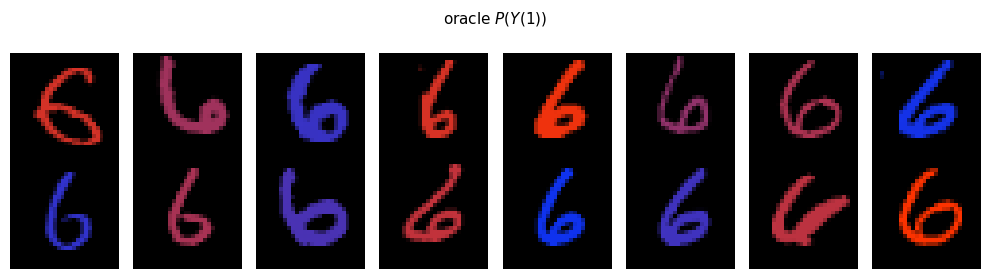

In [8]:
def show_grid(images, title, in_model_range=True):
    fig, axes = plt.subplots(2, 8, figsize=(10, 2.8))
    for image, ax in zip(images[:16], axes.flatten()):
        shown = to_image_range(image) if in_model_range else image
        ax.imshow(shown.permute(1, 2, 0).cpu().numpy())
        ax.axis("off")
    fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    plt.show()


with torch.no_grad():
    show_grid(ae.decode(initial_particles), r"initial particles — observed arm $a=1$ (skew red)")
    for regime in REGIMES:
        base = next(r for r in results if r["regime"] == regime and r["tag"] == "no noise")
        show_grid(ae.decode(base["particles"]), f"{regime} — no noise")
        for mode in ("injected", "additive"):
            r = best[regime][mode]
            show_grid(ae.decode(r["particles"]), f"{regime} — best {mode}: {r['tag']}")
show_grid(Y_oracle, r"oracle $P(Y(1))$", in_model_range=False)

## Summary

- **Neither mechanism helps a flow that is not stuck.** In the well-conditioned regime the
  best injected and best additive settings only *tie* the noise-free baseline
  ($\mathrm{SW}_2 = 0.0137$ vs the oracle floor $0.0081$), and every larger scale is worse.
  The optimum is $\beta \to 0$; the same verdict holds for a narrow-IMQ variant of the
  regime that merely transports slowly.
- **They fail on scales two orders of magnitude apart.** Additive noise at
  $\beta = 0.003$ is about as damaging as injected noise at $\beta = 0.3$, matching the
  mechanism: additive displaces a particle by $\beta$ per step, injected only through the
  induced change in the gradient. The two must never be swept on a shared grid.
- **The bias of additive noise is directly visible.** Under annealing the injected runs
  return to the noise-free objective ($\beta = 1$: $\mathrm{SW}_2$ $0.0460 \to 0.0155$,
  objective $1.2\mathrm{e}{-3} \to 2.7\mathrm{e}{-5}$), because injected noise does not move
  the minimiser. The additive runs at constant $\beta$ settle at an inflated objective
  ($4.5\mathrm{e}{-2}$ at $\beta = 0.03$) — the entropy-biased equilibrium of the Langevin
  dynamics, which annealing mitigates but does not undo.
- **Keep $\beta$ below the kernel bandwidth.** The transport column shows why: injected
  noise at $\beta = 1$ flattens the mollified velocity field and nearly freezes the flow
  ($3.31 \to 0.51$), while additive noise inflates transport without direction
  ($3.31 \to 117.5$). Both large-$\beta$ regimes also collapse sample variance
  (colour sd $0.280 \to 0.158$) and drag the colour law back toward the confounded red,
  undoing the deconfounding the flow is for.
- **In a genuine dead zone the roles reverse.** With the particles displaced outside a
  narrow Gaussian kernel's support, injected noise cannot bridge the gap — averaging
  near-zero gradients over a ball stays near zero — and freezes the flow, whereas additive
  noise diffuses particles until some reach the support and the drift takes over
  ($0.1081 \to 0.0919$, transport $6.3 \to 30.9$). This is the one setting where additive
  noise is the only mechanism that does anything. It is still a poor place to be: every
  dead-zone run stays an order of magnitude above the floor, so the remedy for a dead zone
  is a sensible bandwidth, not noise.
- **Recommendation.** Keep injected noise as the default — it is bias-free and forgiving —
  and enable it only with an annealing schedule and $\beta$ well below the bandwidth. Adopt
  additive noise only when the absolute-continuity guarantees of the Langevin analysis are
  specifically wanted, and then anneal it to zero.